### In this notebook the SS and IF methods of KdV solver are compared with an exact solution to the problem
HSG, 16.09.26

In [17]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from linear.help import *
from nonlinear.kdV import *

The problem for this notebook is the KdV equation
$$ u_t + u_{xxx} + 6uu_x = 0 $$
We shal look at the double solition with initial data $ u(0,x) = -6 \cdot sech^2(x)$ that has a known analytical solution.

In [19]:
def u(t,x):
    t = np.atleast_1d(t)[:,None]
    x = np.atleast_1d(x)[None,:]
    numerator = -12*(3+4*np.cosh(2*x-8*t) + np.cosh(4*x - 64*t))
    denominator = (3*np.cosh(x-28*t)+ np.cosh(3*x-36*t))**2
    return numerator/denominator

def u0(x):
    return -6/(np.cosh(x)**2)

In [23]:
# Set-up
N=2**8
L=40
T = 5
dt_arr = [1e-3, 5e-4, 1e-4, 5e-5]
x = make_x_array(N,L,symmetric=False)

u0_ = u0(x)

e_ss = []
e_if = []

In [ ]:
for dt in dt_arr:
    print(10*'-', dt , 10*'-')
    eq = KdV(u0_, L=L,dt=dt, T=T)
    t,u_ss = eq.solve(method='SS', set=False)
    t_,u_if = eq.solve(method='IF', set=False)
    u_exact = u(t,x)

    e_ss.append(np.mean(np.abs(u_ss- u_exact)))
    e_if.append(np.mean(np.abs(u_if- u_exact)))
    


---------- 0.001 ----------
---------- 0.0005 ----------
---------- 0.0001 ----------
---------- 5e-05 ----------


In [28]:
print(f"Error for SS")
print(e_ss)
print("Error for IF")
print(e_if)
print("Time steps")
print(dt_arr)

Error for SS
[np.float64(10.384902064051225), np.float64(10.425230119489811), np.float64(10.444560942786326), np.float64(10.444526806581477)]
Error for IF
[np.float64(10.386609936048599), np.float64(10.444977353200786), np.float64(10.444767985979075), np.float64(10.444575398278921)]
Time steps
[0.001, 0.0005, 0.0001, 5e-05]


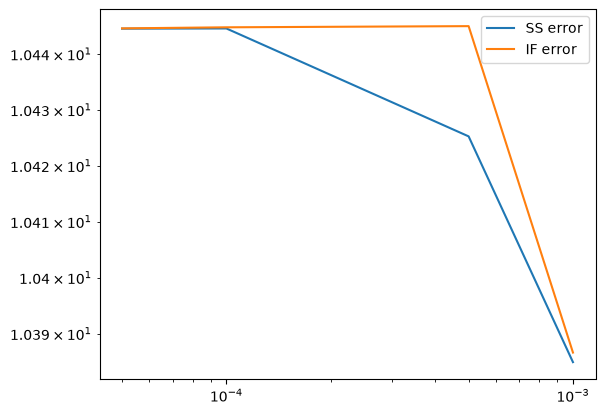

In [27]:
plt.loglog(dt_arr, e_ss, label = "SS error")
plt.loglog(dt_arr, e_if, label = "IF error")
plt.legend()
plt.show()